<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df=pd.read_csv('/content/drive/MyDrive/TeachingRatings.csv')
df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


Q1. T-Test: Using the teachers' rating data set, does gender affect teaching evaluation rates?

Male mean: 4.0690298507462686
Female mean: 3.901025641025641
T-statistic: 3.2667110010009375
P-value: 0.0011761043559350435
Decision: Reject H0


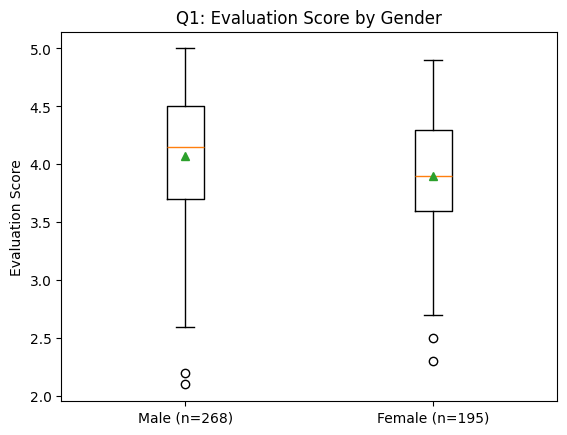


1. Male mean = 4.069, female mean = 3.901, a difference of 0.168 points in favour of males.
2. t = 3.267, p = 0.0012, which is below alpha = 0.05. Decision: Reject H0. Gender is related to evaluation scores.
3. The 95% confidence interval for the difference is [0.067, 0.269]. It does not contain 0, which agrees with the rejection.
4. Cohen's d = 0.31. Values near 0.2 are a small effect, so the difference is real but small. The boxes overlap heavily.
5. This matches Practical 7 (regression gave t = 3.25, p = 0.001). A t-test and a regression on a 0/1 dummy are the same test.



In [8]:
male = df[df['gender'] == 'male']['eval']
female = df[df['gender'] == 'female']['eval']

t_stat, p_val = stats.ttest_ind(male, female, equal_var=False)   # Welch's t-test

diff = male.mean() - female.mean()
se = np.sqrt(male.var()/len(male) + female.var()/len(female))
ci_low, ci_high = diff - 1.96*se, diff + 1.96*se                  # 95% CI for the difference
pooled_sd = np.sqrt(((len(male)-1)*male.var() + (len(female)-1)*female.var()) / (len(male)+len(female)-2))
cohen_d = diff / pooled_sd                                         # effect size

alpha = 0.05
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"

print("Male mean:", male.mean())
print("Female mean:", female.mean())
print("T-statistic:", t_stat)
print("P-value:", p_val)
print("Decision:", decision)

# Graph: boxplot with means
plt.boxplot([male, female], showmeans=True)
plt.xticks([1, 2], [f'Male (n={len(male)})', f'Female (n={len(female)})'])
plt.ylabel("Evaluation Score")
plt.title("Q1: Evaluation Score by Gender")
plt.show()

print(f"""
1. Male mean = {male.mean():.3f}, female mean = {female.mean():.3f}, a difference of {diff:.3f} points in favour of males.
2. t = {t_stat:.3f}, p = {p_val:.4f}, which is below alpha = {alpha}. Decision: {decision}. Gender is related to evaluation scores.
3. The 95% confidence interval for the difference is [{ci_low:.3f}, {ci_high:.3f}]. It does not contain 0, which agrees with the rejection.
4. Cohen's d = {cohen_d:.2f}. Values near 0.2 are a small effect, so the difference is real but small. The boxes overlap heavily.
5. This matches Practical 7 (regression gave t = 3.25, p = 0.001). A t-test and a regression on a 0/1 dummy are the same test.
""")

Q2. ANOVA: Using the teachers' rating data set, does beauty score for instructors differ by age?

               mean       std  count
age_group                           
<=35       0.452591  0.924458     64
36-45      0.080148  0.755178    111
46-55     -0.013876  0.705476    158
56+       -0.274384  0.731334    130
F-statistic: 13.71586379326857
P-value: 1.3941486900308506e-08
Decision: Reject H0
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)      0.372     0.010     0.066     0.679
 (0 - 2)      0.466     0.000     0.177     0.756
 (0 - 3)      0.727     0.000     0.429     1.025
 (1 - 0)     -0.372     0.010    -0.679    -0.066
 (1 - 2)      0.094     0.749    -0.148     0.336
 (1 - 3)      0.355     0.002     0.102     0.607
 (2 - 0)     -0.466     0.000    -0.756    -0.177
 (2 - 1)     -0.094     0.749    -0.336     0.148
 (2 - 3)      0.261     0.020     0.029     0.492
 (3 - 0)     -0.727     0.000    -1.025    -0.429
 (3 - 1)     -0.355     0.002    -0.607    -0.102
 (3 - 2)     -0.261     0.020    -0.492

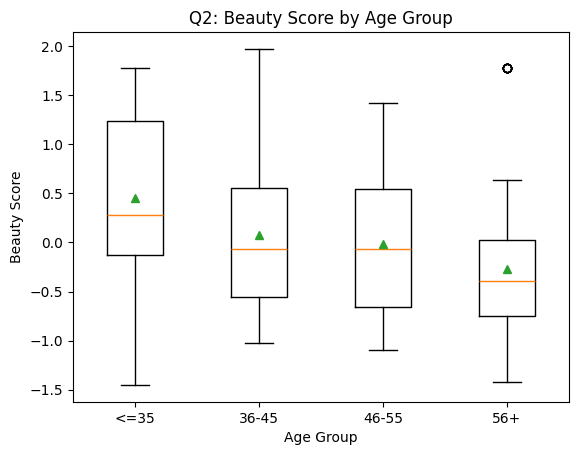


1. ANOVA compares 4 group means at once. Running many t-tests instead would inflate the chance of a false positive.
2. F = 13.72 with df = (3, 459), p = 1.39e-08, far below 0.05. Decision: Reject H0. At least one age group has a different mean beauty score.
3. The means fall steadily with age: 0.45 (<=35) down to -0.27 (56+). Younger instructors have higher beauty ratings on average.
4. Eta squared = 0.082, so age group explains about 8.2% of the variation in beauty. That is a real but modest effect.
5. ANOVA does not say WHICH groups differ. The Tukey HSD table above does: pairs with p < 0.05 are significantly different.
6. Practical 7 used 3 age groups (F = 17.60). The F value changes with the cut points, but the conclusion is the same.



In [9]:
bins = [0, 35, 45, 55, 100]
labels = ['<=35', '36-45', '46-55', '56+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)

groups = [g['beauty'].values for _, g in df.groupby('age_group', observed=True)]
f_stat, p_val = stats.f_oneway(*groups)

k = len(groups)
N = sum(len(g) for g in groups)
grand_mean = df['beauty'].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
ss_total = ((df['beauty'] - grand_mean)**2).sum()
eta_sq = ss_between / ss_total                                     # effect size

stats_table = df.groupby('age_group', observed=True)['beauty'].agg(['mean', 'std', 'count'])
print(stats_table)
print("F-statistic:", f_stat)
print("P-value:", p_val)

decision = "Reject H0" if p_val < 0.05 else "Fail to reject H0"
print("Decision:", decision)

# Post-hoc: which pairs differ?
print(stats.tukey_hsd(*groups))

# Graph: boxplot per age group
plt.boxplot(groups, showmeans=True)
plt.xticks(range(1, k+1), labels)
plt.xlabel("Age Group")
plt.ylabel("Beauty Score")
plt.title("Q2: Beauty Score by Age Group")
plt.show()

print(f"""
1. ANOVA compares {k} group means at once. Running many t-tests instead would inflate the chance of a false positive.
2. F = {f_stat:.2f} with df = ({k-1}, {N-k}), p = {p_val:.2e}, far below 0.05. Decision: {decision}. At least one age group has a different mean beauty score.
3. The means fall steadily with age: {stats_table['mean'].iloc[0]:.2f} (<=35) down to {stats_table['mean'].iloc[-1]:.2f} (56+). Younger instructors have higher beauty ratings on average.
4. Eta squared = {eta_sq:.3f}, so age group explains about {eta_sq*100:.1f}% of the variation in beauty. That is a real but modest effect.
5. ANOVA does not say WHICH groups differ. The Tukey HSD table above does: pairs with p < 0.05 are significantly different.
6. Practical 7 used 3 age groups (F = 17.60). The F value changes with the cut points, but the conclusion is the same.
""")

Q3. Chi-square: Using the teachers' rating data set, is there an association between tenure and gender?

gender  female  male
tenure              
no          50    52
yes        145   216

Expected counts if independent:
gender  female   male
tenure               
no        43.0   59.0
yes      152.0  209.0
Chi2-statistic: 2.20678166999886
Degrees of freedom: 1
P-value: 0.1374050603563787
Decision: Fail to reject H0


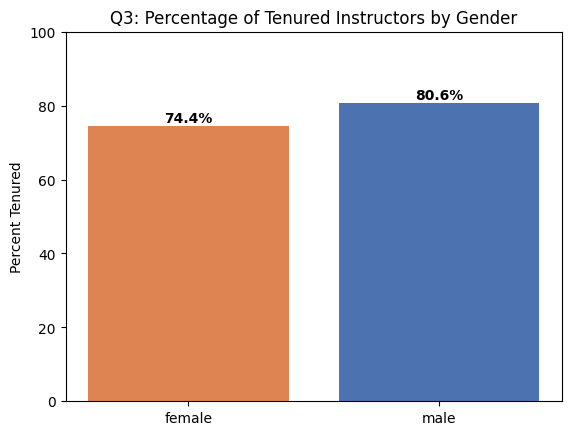


1. Chi-square compares the observed counts with the counts expected if tenure and gender were independent. It works on categorical variables.
2. 74.4% of female and 80.6% of male instructors are tenured, a gap of 6.2 percentage points.
3. Chi2 = 2.207, df = 1, p = 0.1374, which is above 0.05. Decision: Fail to reject H0. There is no significant association between tenure and gender.
4. Cramer's V = 0.069 (0 = no association, 1 = perfect), so the link is very weak.
5. The gap in the sample could easily be due to chance. This matches the finding in Practical 2.
6. Validity check: all expected counts are above 5 (see the expected table), so the chi-square test is reliable here.



In [10]:
ct = pd.crosstab(df['tenure'], df['gender'])
chi2, p_val, dof, expected = stats.chi2_contingency(ct)

n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
pct_within_gender = ct.div(ct.sum(axis=0), axis=1) * 100           # % within each gender

print(ct)
print("\nExpected counts if independent:")
print(pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(1))
print("Chi2-statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_val)

decision = "Reject H0" if p_val < 0.05 else "Fail to reject H0"
print("Decision:", decision)

# Graph: % tenured within each gender
tenured_pct = pct_within_gender.loc['yes']
plt.bar(tenured_pct.index, tenured_pct.values, color=['#DD8452', '#4C72B0'])
for i, v in enumerate(tenured_pct.values):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')
plt.ylabel("Percent Tenured")
plt.title("Q3: Percentage of Tenured Instructors by Gender")
plt.ylim(0, 100)
plt.show()

print(f"""
1. Chi-square compares the observed counts with the counts expected if tenure and gender were independent. It works on categorical variables.
2. {tenured_pct['female']:.1f}% of female and {tenured_pct['male']:.1f}% of male instructors are tenured, a gap of {abs(tenured_pct['male'] - tenured_pct['female']):.1f} percentage points.
3. Chi2 = {chi2:.3f}, df = {dof}, p = {p_val:.4f}, which is above 0.05. Decision: {decision}. There is no significant association between tenure and gender.
4. Cramer's V = {cramers_v:.3f} (0 = no association, 1 = perfect), so the link is very weak.
5. The gap in the sample could easily be due to chance. This matches the finding in Practical 2.
6. Validity check: all expected counts are above 5 (see the expected table), so the chi-square test is reliable here.
""")

Q4. Correlation: Using the teachers rating dataset, Is teaching evaluation score correlated with beauty score?

Pearson r: 0.18903909062278274
P-value: 4.247115507786e-05
Spearman rho: 0.16403522727034867
Decision: Reject H0


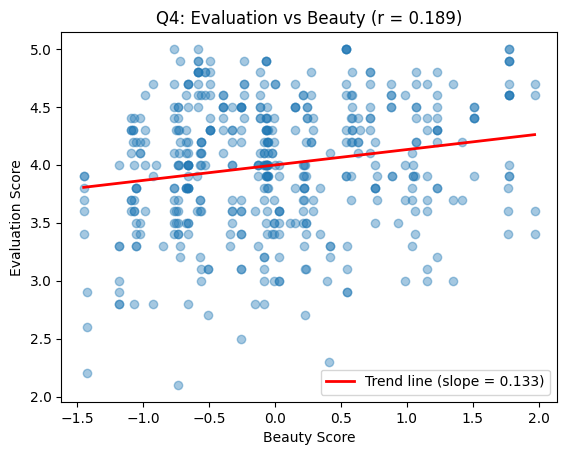


1. r = 0.189: a positive but weak linear relationship. Higher beauty scores go with slightly higher evaluations.
2. p = 4.25e-05, which is below 0.05. Decision: Reject H0. The correlation is statistically significant, so it is unlikely to be zero in the population.
3. r squared = 0.036, so beauty explains only about 3.6% of the variation in evaluations. This matches R squared = 0.036 in Practical 7.
4. The points form a wide cloud around the trend line, so beauty is a poor predictor of any single instructor's rating.
5. Spearman rho = 0.164 (rank-based) agrees with Pearson, so the result is not driven by outliers.
6. Correlation is not causation. Students may rate attractive instructors higher, but a third factor could drive both.



In [11]:
r, p_val = stats.pearsonr(df['eval'], df['beauty'])
rho, p_rho = stats.spearmanr(df['eval'], df['beauty'])             # rank-based check

print("Pearson r:", r)
print("P-value:", p_val)
print("Spearman rho:", rho)

decision = "Reject H0" if p_val < 0.05 else "Fail to reject H0"
print("Decision:", decision)

# Graph: scatter with trend line
m, c = np.polyfit(df['beauty'], df['eval'], 1)
xs = np.linspace(df['beauty'].min(), df['beauty'].max(), 100)
plt.scatter(df['beauty'], df['eval'], alpha=0.4)
plt.plot(xs, m*xs + c, color='red', linewidth=2, label=f"Trend line (slope = {m:.3f})")
plt.xlabel("Beauty Score")
plt.ylabel("Evaluation Score")
plt.title(f"Q4: Evaluation vs Beauty (r = {r:.3f})")
plt.legend()
plt.show()

print(f"""
1. r = {r:.3f}: a positive but weak linear relationship. Higher beauty scores go with slightly higher evaluations.
2. p = {p_val:.2e}, which is below 0.05. Decision: {decision}. The correlation is statistically significant, so it is unlikely to be zero in the population.
3. r squared = {r**2:.3f}, so beauty explains only about {r**2*100:.1f}% of the variation in evaluations. This matches R squared = 0.036 in Practical 7.
4. The points form a wide cloud around the trend line, so beauty is a poor predictor of any single instructor's rating.
5. Spearman rho = {rho:.3f} (rank-based) agrees with Pearson, so the result is not driven by outliers.
6. Correlation is not causation. Students may rate attractive instructors higher, but a third factor could drive both.
""")